In [1]:
import autograd.numpy as anp
from autograd import value_and_grad
import nlopt
import matplotlib.pyplot as plt
import problems
import topo_api

class PixelModel:
    def __init__(self, args, seed=None):
        self.seed = seed
        if seed is not None:
            anp.random.seed(seed)
        self.env = topo_api.Environment(args)
        self.nely = self.env.args['nely']
        self.nelx = self.env.args['nelx']
        self.volfrac = self.env.args['volfrac']
        self.z = anp.ones((self.nely, self.nelx)) * self.volfrac

    def get_design(self):
        """
        forward: latent z -> density field x
        """
        return self.z
    
def density_from_gaussian_beams(x_var, n_shapes, nely=50, nelx=100):
    field_total = anp.zeros(nely*nelx)
    for i in range(n_shapes):
        xi = x_var[i*5:(i+1)*5]
        w, h, theta, tx, ty = xi
        sigma = 1
        x = anp.arange(nelx)
        y = anp.arange(nely)
        xv, yv = anp.meshgrid(x, y)
        cx = tx
        cy = ty
        xt = xv - cx
        yt = yv - cy
        # xt = tx
        # yt = ty
        cos_t = anp.cos(theta)
        sin_t = anp.sin(theta)
        x_rot = cos_t * xt + sin_t * yt
        y_rot = -sin_t * xt + cos_t * yt
        dx = x_rot / (w / 2)
        dy = y_rot / (h / 2)
        r2 = dx**2 + dy**2
        # field = anp.exp(-r2 / (2 * sigma**2)) * anp.exp(-anp.maximum(0, r2 - 1.0) * 50)
        field = anp.exp(-r2 / (2 * sigma**2))
        field_total += field.ravel()
    return field_total

def ends_to_gaussian_beams(p_var, n_shapes, nely=50, nelx=100):
    x_var = []
    for i in range(n_shapes):
        xi = p_var[i*4:(i+1)*4]
        x1, y1, x2, y2 = xi
        tx = 0.5 * (x1 + x2)
        ty = 0.5 * (y1 + y2)
        dx = x2 - x1
        dy = y2 - y1
        length = anp.sqrt(dx**2 + dy**2)
        theta = -anp.arctan2(dx, dy) 
        w = 1.0
        if length == 0:
            h = 1
        else:
            h = length*0.6
        # sigma = 2.0
        x_var.extend([w, h, theta, tx, ty])

    x_var = anp.array(x_var)
    return density_from_gaussian_beams(x_var, n_shapes, nely, nelx)


def length_loss(x_var, n_shapes, target_lens):
    lengths = []
    for i in range(n_shapes):
        x1, y1, x2, y2 = x_var[4*i : 4*i+4]
        length = anp.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        lengths.append(length)
    lengths = anp.array(lengths)
    loss = anp.sum((lengths - target_lens)**2)
    return loss

def self_intersection_loss(x_var, n_shapes, nely=50, nelx=100):
    dens = ends_to_gaussian_beams(x_var, n_shapes, nely=nely, nelx=nelx)
    overflow = anp.maximum(dens - 1.0, 0.0)
    return anp.sum((overflow+1)**4)

def self_intersection_loss_ipc(x_var, n_shapes, nely=50, nelx=100, alpha=10.0):
    dens = ends_to_gaussian_beams(x_var, n_shapes, nely=nely, nelx=nelx)
    overflow = dens - 1.0
    loss = anp.sum(anp.log1p(anp.exp(alpha * overflow)) / alpha)
    return loss

def joint_attaching_loss(x_var, n_shapes, target_dist=None):
    points = []
    for i in range(n_shapes):
        x1, y1, x2, y2 = x_var[4*i : 4*i+4]
        points.append(anp.array([x1, y1]))
        points.append(anp.array([x2, y2]))
    
    points = anp.stack(points)
    n_points = points.shape[0]
    
    loss = 0.0
    for i in range(n_points):
        for j in range(i+1, n_points):
            dist = anp.sqrt(anp.sum((points[i]-points[j])**2))
            if target_dist is None:
                loss += dist**2
            else:
                loss += (dist - target_dist)**2
    return loss


def run_mma(env, n_shapes=2, max_iterations=50, refresh_every=1, 
                                      max_volume_fraction=0.5, target_lens=None, x0 = None):
    nely, nelx = env.args['nely'], env.args['nelx']
    if x0 is None:
        x0 = []
        for i in range(n_shapes):
            tx1_init = anp.random.uniform(0, nelx)
            ty1_init = anp.random.uniform(0, nely)
            tx2_init = anp.random.uniform(0, nelx)
            ty2_init = anp.random.uniform(0, nely)
            x0.extend([tx1_init, ty1_init, tx2_init, ty2_init])
        x0 = anp.array(x0, dtype=anp.float64)
    

    losses = []
    frames = []

    plt.ion()
    fig, ax = plt.subplots()
    dens = ends_to_gaussian_beams(x0, n_shapes, nely=nely, nelx=nelx)
    im = ax.imshow(dens.reshape(nely, nelx), cmap='viridis', origin='lower', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax)

    def objective_fn(x_var):
        dens = ends_to_gaussian_beams(x_var, n_shapes, nely=nely, nelx=nelx)
        return env.objective(dens, volume_constraint=False) + length_loss(x_var, n_shapes, target_lens) \
            + self_intersection_loss(x_var, n_shapes, nelx, nely)

    def wrap_autograd_func(func):
        def wrapper(x, grad_out):
            value, g = value_and_grad(func)(x)
            if grad_out.size > 0:
                grad_out[:] = g.ravel()
            dens = ends_to_gaussian_beams(x, n_shapes, nely, nelx)
            dens = anp.where(dens > 0.5, 1, dens)
            true_value = env.objective(dens, volume_constraint=False)
            losses.append(true_value)
            frames.append(anp.array(x, dtype=anp.float64))
            return value
        return wrapper

    # w, h, theta, tx, ty, sigma
    opt = nlopt.opt(nlopt.LD_MMA, 4*n_shapes) # GN_CRS2_LM LD_MMA
    lower = [0,0,0,0]*n_shapes
    upper = [nelx,nely,nelx,nely]*n_shapes
    opt.set_lower_bounds(lower)
    opt.set_upper_bounds(upper)
    opt.set_min_objective(wrap_autograd_func(objective_fn))
    opt.set_maxeval(max_iterations)
    opt.set_xtol_rel(1e-6)
    opt.set_xtol_abs(1e-8)

    x_opt = opt.optimize(x0)
    # for i, x_var in enumerate(frames):
    #     dens = ends_to_gaussian_beams(x_var, n_shapes, nely=nely, nelx=nelx)
    #     im.set_data(dens.reshape(nely, nelx))
    #     ax.set_title(f"Iteration {i+1}, Loss: {losses[i]:.6f}")
    #     plt.pause(0.05)

    designs = [ends_to_gaussian_beams(f, n_shapes, nely=nely, nelx=nelx).reshape(nely, nelx) for f in frames]
    return losses, frames, frames[-1]

def generate_lengths_normal(mean, std, n, min_val, max_val):
    lengths = anp.random.normal(mean, std, size=n)
    lengths = anp.clip(lengths, min_val, max_val)
    return lengths




In [2]:
def add_random_beams(x_var, n_new, nelx, nely):
    new_vars = []
    for _ in range(n_new):
        x1 = anp.random.uniform(0, nelx)
        y1 = anp.random.uniform(0, nely)
        x2 = anp.random.uniform(0, nelx)
        y2 = anp.random.uniform(0, nely)
        new_vars.extend([x1, y1, x2, y2])
    
    new_vars = anp.array(new_vars)
    
    return anp.concatenate([x_var, new_vars])

In [3]:
def point_to_segment_dist(p, a, b):
    ap = p - a
    ab = b - a
    t = anp.dot(ap, ab) / (anp.dot(ab, ab) + 1e-8)
    t = anp.clip(t, 0.0, 1.0)
    proj = a + t * ab
    return anp.linalg.norm(p - proj)


def prune_beams_and_xvar(x_var, threshold=0.2):
    beams = x_var.reshape((-1, 4))
    n = beams.shape[0]

    keep_mask = anp.ones(n, dtype=bool)

    for i, beam in enumerate(beams):
        x1, y1, x2, y2 = beam
        endpoints = anp.array([[x1, y1], [x2, y2]])

        beam_len = anp.sqrt((x1-x2)**2 + (y1-y2)**2)

        for ep in endpoints:
            has_neighbor = False

            for j, other in enumerate(beams):
                if i == j:
                    continue

                ox1, oy1, ox2, oy2 = other
                p1 = anp.array([ox1, oy1])
                p2 = anp.array([ox2, oy2])

                d1 = anp.linalg.norm(ep - p1)
                d2 = anp.linalg.norm(ep - p2)

                d_line = point_to_segment_dist(ep, p1, p2)

                # add manually
                if (ep[1] <= 3):
                    has_neighbor = True
                    break
                elif (anp.sqrt((ep[0]-nelx)**2 + (ep[1]-nely)**2) < 4):
                    has_neighbor = True
                    break

                if (
                    d1 < beam_len * threshold or
                    d2 < beam_len * threshold or
                    d_line < beam_len * threshold
                ):
                    has_neighbor = True
                    break

            if not has_neighbor:
                keep_mask[i] = False
                break

    new_beams = beams[keep_mask]
    new_x_var = new_beams.reshape(-1)

    return new_beams, new_x_var, keep_mask

In [4]:
import pulp
import numpy as np

def assign_inventory_to_beams(beams, inventory_lengths):
    n_beams = beams.shape[0]
    member_lengths = np.linalg.norm(beams[:, 2:4] - beams[:, 0:2], axis=1)

    num_inventory = len(inventory_lengths)

    prob = pulp.LpProblem("InventoryAssignment", pulp.LpMinimize)

    x = pulp.LpVariable.dicts(
        "x",
        ((i, j) for i in range(n_beams) for j in range(num_inventory)),
        cat="Binary"
    )

    prob += pulp.lpSum(
        x[(i, j)] * (inventory_lengths[j] - member_lengths[i])
        for i in range(n_beams)
        for j in range(num_inventory)
    )

    for i in range(n_beams):
        prob += pulp.lpSum(x[(i, j)] for j in range(num_inventory)) == 1

    for i in range(n_beams):
        for j in range(num_inventory):
            if inventory_lengths[j] < member_lengths[i]:
                prob += x[(i, j)] == 0

    for j in range(num_inventory):
        prob += pulp.lpSum(x[(i, j)] for i in range(n_beams)) <= 1

    prob.solve(pulp.PULP_CBC_CMD(msg=0))

    assignment_dict = {}
    target_lengths = np.zeros(n_beams)
    for i in range(n_beams):
        for j in range(num_inventory):
            if pulp.value(x[(i, j)]) == 1:
                assignment_dict[i] = j
                target_lengths[i] = inventory_lengths[j]

    return target_lengths, assignment_dict

Beam 1: Start=(1.01, 32.09), End=(13.05, 20.49)
Beam 2: Start=(45.85, 41.21), End=(37.90, 60.24)
Beam 3: Start=(96.36, 32.65), End=(99.32, 63.46)
Beam 4: Start=(0.28, 0.00), End=(14.45, 17.68)
Beam 5: Start=(77.21, 23.74), End=(53.55, 8.34)
Beam 6: Start=(65.06, 51.36), End=(100.00, 39.23)
Beam 7: Start=(27.94, 38.83), End=(38.96, 56.16)
Beam 8: Start=(15.67, 19.33), End=(27.37, 37.75)
Beam 9: Start=(7.19, 62.35), End=(0.00, 80.00)
Beam 10: Start=(27.67, 4.82), End=(60.33, 11.14)
Beam 11: Start=(70.86, 48.90), End=(39.34, 59.00)
Beam 12: Start=(85.43, 29.19), End=(100.00, 40.44)
Beam 13: Start=(14.79, 69.86), End=(44.51, 57.02)
Beam 14: Start=(93.13, 34.97), End=(70.62, 19.55)
Beam 15: Start=(99.71, 61.93), End=(98.83, 78.10)
Beam 16: Start=(0.00, 0.05), End=(18.52, 3.34)
Beam 17: Start=(22.27, 66.51), End=(0.00, 76.81)
Beam 18: Start=(34.14, 6.18), End=(14.37, 2.61)
Beam 19: Start=(51.34, 22.05), End=(44.30, 43.75)
Beam 20: Start=(58.31, 7.21), End=(47.42, 37.38)


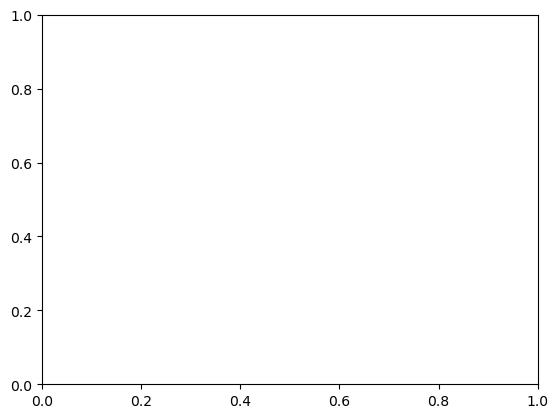

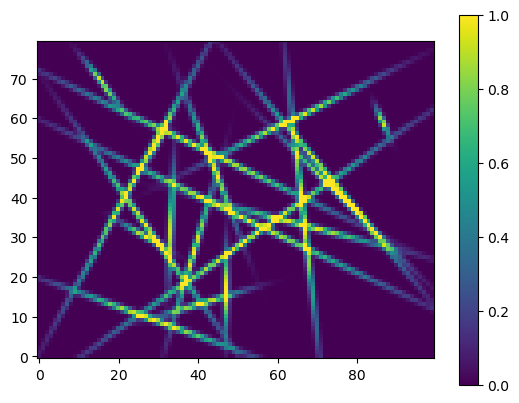

In [26]:
problem = problems.example5(height=80, width=100)
args = topo_api.specified_task(problem)
model = PixelModel(args=args)  

# w, h, theta, tx, ty, sigma
x0 = [40,30,70,30]

plt.ion()

fig, ax = plt.subplots()
# dens = ends_to_gaussian_beams(x0, 1, nely=nely, nelx=nelx)
# im = ax.imshow(dens.reshape(nely, nelx), cmap='viridis', origin='lower', vmin=0, vmax=1)
# fig.colorbar(im, ax=ax)
n_inventory = 40
n_shapes = 20

inventory = generate_lengths_normal(mean=20, std=5, n=n_inventory, min_val=10, max_val=30)
selected_lengths = anp.random.choice(inventory, size=n_shapes, replace=False)
_, frames, last_var = run_mma(model.env, n_shapes, 500,target_lens = selected_lengths)

beams = last_var.reshape((n_shapes, 4))
for i, beam in enumerate(beams):
    x1, y1, x2, y2 = beam
    print(f"Beam {i+1}: Start=({x1:.2f}, {y1:.2f}), End=({x2:.2f}, {y2:.2f})")

beam_dist_threshold = 10
node_dist_threshold = 10

plt.ioff()
plt.show()

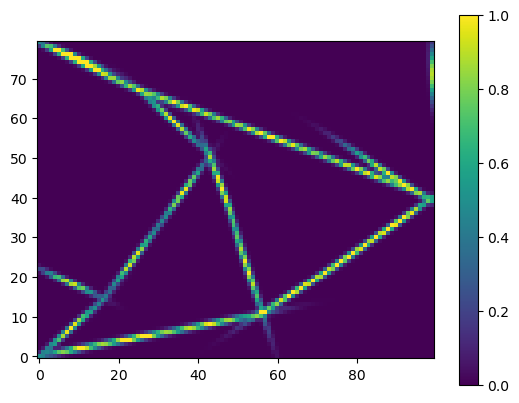

In [31]:
_, frames, last_var = run_mma(model.env, n_shapes, 500,target_lens = selected_lengths, x0= frames[-1])

beams = last_var.reshape((n_shapes, 4))

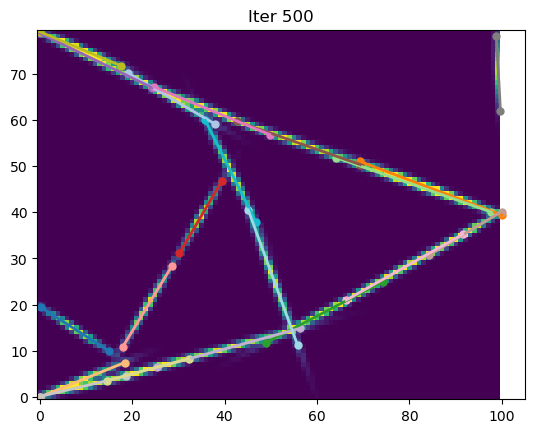

In [32]:
from IPython.display import clear_output
beams = last_var.reshape((n_shapes, 4))
nely, nelx = model.env.args['nely'], model.env.args['nelx']

for i, x_var in enumerate(frames):
    dens = ends_to_gaussian_beams(x_var, beams.shape[0], nely=nely, nelx=nelx)

    ax.clear()

    im = ax.imshow(
        dens.reshape(nely, nelx),
        cmap='viridis',
        origin='lower',
        vmin=0,
        vmax=1,
        # extent=[0, 80, 0, 100]
    )

    beams = x_var.reshape((beams.shape[0], 4))

    for j, beam in enumerate(beams):
        x1, y1, x2, y2 = beam
        color = plt.cm.tab20(j % 20)

        ax.scatter([x1, x2], [y1, y2], color=color, s=25)
        ax.plot([x1, x2], [y1, y2], color=color, linewidth=2)

    ax.set_title(f"Iter {i+1}")
    ax.set_aspect('equal')

    clear_output(wait=True)
    display(fig)

    plt.pause(0.01)

In [22]:
x_var = frames[-1]

beams, new_x_var, mask = prune_beams_and_xvar(x_var, threshold=0.5)

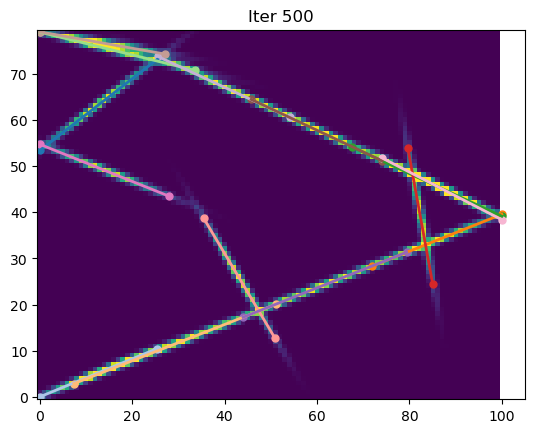

In [23]:
dens = ends_to_gaussian_beams(new_x_var, beams.shape[0], nely=nely, nelx=nelx)

ax.clear()

im = ax.imshow(
    dens.reshape(nely, nelx),
    cmap='viridis',
    origin='lower',
    vmin=0,
    vmax=1,
    # extent=[0, 80, 0, 100]
)

beams = new_x_var.reshape((beams.shape[0], 4))

for j, beam in enumerate(beams):
    x1, y1, x2, y2 = beam
    color = plt.cm.tab20(j % 20)

    ax.scatter([x1, x2], [y1, y2], color=color, s=25)
    ax.plot([x1, x2], [y1, y2], color=color, linewidth=2)

ax.set_title(f"Iter {i+1}")
ax.set_aspect('equal')

clear_output(wait=True)
display(fig)

In [9]:
assigned_lengths, assignment = assign_inventory_to_beams(beams, inventory)

In [10]:
from IPython.display import clear_output

nely, nelx = model.env.args['nely'], model.env.args['nelx']

for i, x_var in enumerate(frames):
    dens = ends_to_gaussian_beams(x_var, beams.shape[0], nely=nely, nelx=nelx)

    ax.clear()

    im = ax.imshow(
        dens.reshape(nely, nelx),
        cmap='viridis',
        origin='lower',
        vmin=0,
        vmax=1,
        # extent=[0, 80, 0, 100]
    )

    beams = x_var.reshape((beams.shape[0], 4))

    for j, beam in enumerate(beams):
        x1, y1, x2, y2 = beam
        color = plt.cm.tab20(j % 20)

        ax.scatter([x1, x2], [y1, y2], color=color, s=25)
        ax.plot([x1, x2], [y1, y2], color=color, linewidth=2)

    ax.set_title(f"Iter {i+1}")
    ax.set_aspect('equal')

    clear_output(wait=True)
    display(fig)

    plt.pause(0.01)

ValueError: cannot reshape array of size 40 into shape (9,4)